In [2]:
import os

print(os.getcwd())
print(os.listdir("../02_data/processed/"))

c:\Users\chamm\Downloads\olist-ecommerce-analytics\03_notebooks
['dataset_summary.csv', 'orders_clean.csv']


In [3]:
import pandas as pd

orders = pd.read_csv("../02_data/processed/orders_clean.csv")

print("Orders shape:", orders.shape)
orders.head()

Orders shape: (99441, 19)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,delivery_delay_days,delivery_performance,approval_date_missing,purchase_date,purchase_year,purchase_month,purchase_day,purchase_day_of_week,purchase_year_month,is_completed
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.0,-8.0,Early,False,2017-10-02,2017,10,2,Monday,2017-10,True
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.0,-6.0,Early,False,2018-07-24,2018,7,24,Tuesday,2018-07,True
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.0,-18.0,Early,False,2018-08-08,2018,8,8,Wednesday,2018-08,True
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.0,-13.0,Early,False,2017-11-18,2017,11,18,Saturday,2017-11,True
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.0,-10.0,Early,False,2018-02-13,2018,2,13,Tuesday,2018-02,True


In [4]:
total_orders = orders["order_id"].nunique()
completed_orders = orders["is_completed"].sum()
completion_rate = completed_orders / total_orders * 100

print(f"Total orders: {total_orders:,}")
print(f"Completed orders: {completed_orders:,}")
print(f"Completion rate: {completion_rate:.2f}%")

Total orders: 99,441
Completed orders: 96,478
Completion rate: 97.02%


In [5]:
order_items = pd.read_csv(
    "../02_data/raw/olist_order_items_dataset.csv"
)

print("Order items shape:", order_items.shape)
order_items.head()

Order items shape: (112650, 7)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [6]:
total_product_revenue = order_items["price"].sum()
total_freight = order_items["freight_value"].sum()

print(f"Total product revenue: €{total_product_revenue:,.2f}")
print(f"Total freight value: €{total_freight:,.2f}")

Total product revenue: €13,591,643.70
Total freight value: €2,251,909.54


In [7]:
delivered_items = order_items.merge(
    orders.loc[
        orders["order_status"] == "delivered",
        ["order_id", "customer_id"]
    ],
    on="order_id",
    how="inner"
)

In [8]:
print("Delivered item rows:", len(delivered_items))
print("Unique delivered orders:", delivered_items["order_id"].nunique())

Delivered item rows: 110197
Unique delivered orders: 96478


In [10]:
delivered_revenue = delivered_items["price"].sum()
delivered_freight = delivered_items["freight_value"].sum()

# Total transaction value = product price + freight
delivered_transaction_value = (
    delivered_items["price"] + delivered_items["freight_value"]
).sum()

print(f"Delivered product revenue: €{delivered_revenue:,.2f}")
print(f"Delivered freight value: €{delivered_freight:,.2f}")
print(f"Delivered transaction value: €{delivered_transaction_value:,.2f}")

Delivered product revenue: €13,221,498.11
Delivered freight value: €2,198,275.64
Delivered transaction value: €15,419,773.75


In [11]:
delivered_orders_count = delivered_items["order_id"].nunique()

aov = delivered_revenue / delivered_orders_count

print(f"Average Order Value: €{aov:,.2f}")

Average Order Value: €137.04


In [13]:
"purchase_timestamp" in orders.columns

False

In [14]:
delivered_items = delivered_items.merge(
    orders[
        ["order_id", "purchase_year_month"]
    ],
    on="order_id",
    how="left"
)

In [15]:
print(delivered_items.shape)
print(delivered_items["purchase_year_month"].isna().sum())

(110197, 9)
0


In [16]:
delivered_items[
    ["order_id", "purchase_year_month", "price"]
].head()

,order_id,purchase_year_month,price
0,00010242fe8c5a6d1ba2dd792cb16214,2017-09,58.90
1,00018f77f2f0320c557190d7a144bdd3,2017-04,239.90
2,000229ec398224ef6ca0657da4fc703e,2018-01,199.00
3,00024acbcdf0a6daa1e931b038114c75,2018-08,12.99
4,00042b26cf59d7ce69dfabb4e55b4fd9,2017-02,199.90


In [17]:
monthly_revenue = (
    delivered_items
    .groupby("purchase_year_month")
    .agg(
        revenue=("price", "sum"),
        freight=("freight_value", "sum"),
        orders=("order_id", "nunique"),
        units_sold=("order_item_id", "count")
    )
    .reset_index()
)

monthly_revenue["aov"] = (
    monthly_revenue["revenue"] / monthly_revenue["orders"]
)

monthly_revenue["revenue_growth"] = (
    monthly_revenue["revenue"].pct_change() * 100
)

monthly_revenue

,purchase_year_month,revenue,freight,orders,units_sold,aov,revenue_growth
0,2016-09,134.97,8.49,1,3,134.970000,NaN
1,2016-10,40325.11,6165.55,265,313,152.170226,2.977709e+04
2,2016-12,10.90,8.72,1,1,10.900000,-9.997297e+01
3,2017-01,111798.36,15684.01,750,913,149.064480,1.025573e+06
4,2017-02,234223.40,37015.92,1653,1858,141.695947,1.095052e+02
5,2017-03,359198.85,55132.10,2546,2897,141.083602,5.335737e+01
6,2017-04,340669.68,50142.72,2303,2569,147.924307,-5.158471e+00
7,2017-05,489338.25,77513.15,3546,4004,137.997250,4.364009e+01
8,2017-06,421923.37,68127.00,3135,3489,134.584807,-1.377674e+01
9,2017-07,481604.52,84694.56,3872,4416,124.381333,1.414502e+01


In [18]:
monthly_revenue = monthly_revenue.sort_values(
    "purchase_year_month"
).reset_index(drop=True)

In [19]:
monthly_revenue

,purchase_year_month,revenue,freight,orders,units_sold,aov,revenue_growth
0,2016-09,134.97,8.49,1,3,134.970000,NaN
1,2016-10,40325.11,6165.55,265,313,152.170226,2.977709e+04
2,2016-12,10.90,8.72,1,1,10.900000,-9.997297e+01
3,2017-01,111798.36,15684.01,750,913,149.064480,1.025573e+06
4,2017-02,234223.40,37015.92,1653,1858,141.695947,1.095052e+02
5,2017-03,359198.85,55132.10,2546,2897,141.083602,5.335737e+01
6,2017-04,340669.68,50142.72,2303,2569,147.924307,-5.158471e+00
7,2017-05,489338.25,77513.15,3546,4004,137.997250,4.364009e+01
8,2017-06,421923.37,68127.00,3135,3489,134.584807,-1.377674e+01
9,2017-07,481604.52,84694.56,3872,4416,124.381333,1.414502e+01


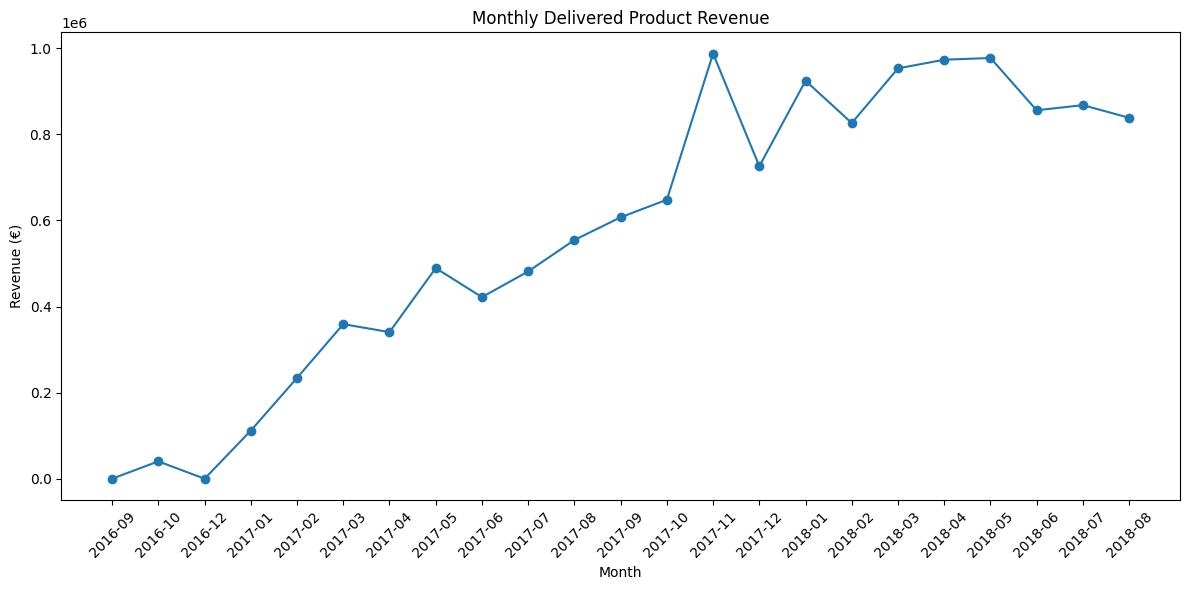

In [20]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue["purchase_year_month"],
    monthly_revenue["revenue"],
    marker="o"
)

plt.title("Monthly Delivered Product Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (€)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

orders = pd.read_csv("../02_data/processed/orders_clean.csv")

order_items = pd.read_csv(
    "../02_data/raw/olist_order_items_dataset.csv"
)

products = pd.read_csv(
    "../02_data/raw/olist_products_dataset.csv"
)

category_translation = pd.read_csv(
    "../02_data/raw/product_category_name_translation.csv"
)

print("orders:", orders.shape)
print("order_items:", order_items.shape)
print("products:", products.shape)
print("category_translation:", category_translation.shape)

orders: (99441, 19)
order_items: (112650, 7)
products: (32951, 9)
category_translation: (71, 2)


In [25]:
delivered_orders = (
    orders[orders["order_status"] == "delivered"]
    [["order_id", "customer_id"]]
)

print(delivered_orders.shape)

(96478, 2)


In [26]:
product_sales = order_items.merge(
    delivered_orders,
    on="order_id",
    how="inner"
)

print(product_sales.shape)

(110197, 8)


In [27]:
product_sales = product_sales.merge(
    products[
        [
            "product_id",
            "product_category_name"
        ]
    ],
    on="product_id",
    how="left"
)

product_sales = product_sales.merge(
    category_translation,
    on="product_category_name",
    how="left"
)

product_sales["category"] = (
    product_sales["product_category_name_english"]
    .fillna("unknown")
)

print(product_sales.shape)

(110197, 11)


In [28]:
category_performance = (
    product_sales
    .groupby("category")
    .agg(
        revenue=("price", "sum"),
        freight_value=("freight_value", "sum"),
        units_sold=("order_item_id", "count"),
        orders=("order_id", "nunique"),
        unique_products=("product_id", "nunique"),
        avg_item_price=("price", "mean")
    )
    .reset_index()
)

category_performance["revenue_share"] = (
    category_performance["revenue"]
    / category_performance["revenue"].sum()
    * 100
)

category_performance = (
    category_performance
    .sort_values("revenue", ascending=False)
    .reset_index(drop=True)
)

category_performance.head(10)

,category,revenue,freight_value,units_sold,orders,unique_products,avg_item_price,revenue_share
0,health_beauty,1233131.72,178957.81,9465,8647,2397,130.283330,9.326717
1,watches_gifts,1166176.98,98156.14,5859,5495,1300,199.040276,8.820309
2,bed_bath_table,1023434.76,201774.50,10953,9272,2991,93.438762,7.740687
3,sports_leisure,954852.55,163404.36,8431,7530,2822,113.254958,7.221969
4,computers_accessories,888724.61,143999.16,7644,6530,1600,116.264339,6.721815
5,furniture_decor,711927.69,168402.23,8160,6307,2593,87.246040,5.384622
6,housewares,615628.69,142763.56,6795,5743,2282,90.600249,4.656270
7,cool_stuff,610204.10,81476.79,3718,3559,770,164.121598,4.615242
8,auto,578966.65,90488.10,4140,3810,1853,139.847017,4.378979
9,toys,471286.48,75774.58,4030,3804,1373,116.944536,3.564547


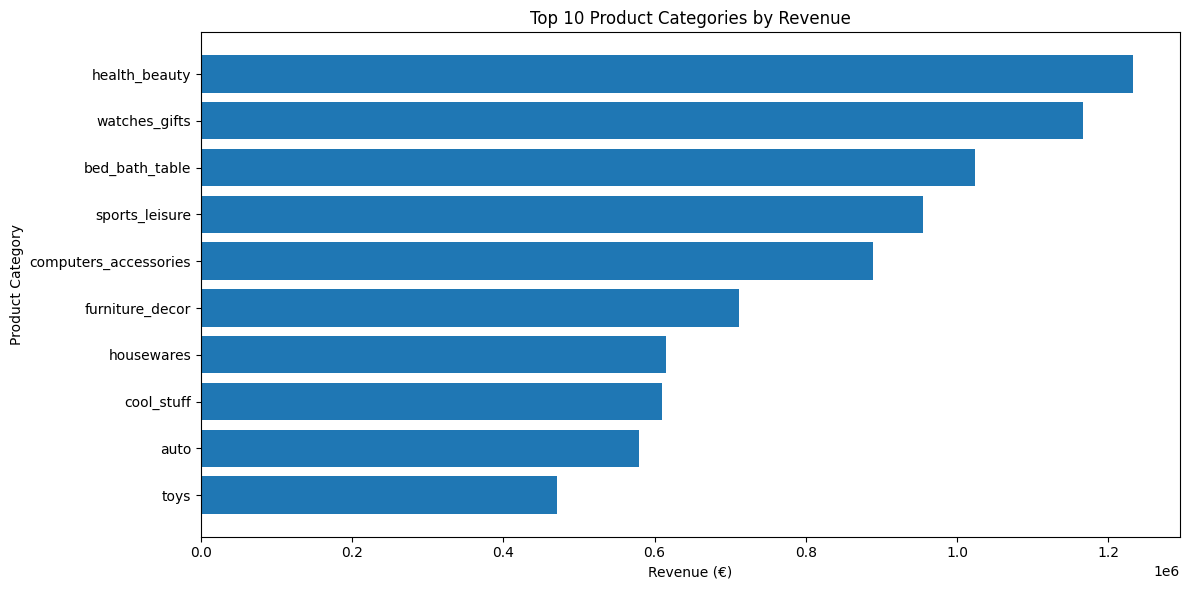

In [29]:
top_categories = category_performance.head(10)

plt.figure(figsize=(12, 6))

plt.barh(
    top_categories["category"][::-1],
    top_categories["revenue"][::-1]
)

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue (€)")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

In [30]:
category_performance["avg_price_per_unit"] = (
    category_performance["revenue"]
    / category_performance["units_sold"]
)

category_performance[
    [
        "category",
        "revenue",
        "units_sold",
        "avg_price_per_unit"
    ]
].head(10)

,category,revenue,units_sold,avg_price_per_unit
0,health_beauty,1233131.72,9465,130.283330
1,watches_gifts,1166176.98,5859,199.040276
2,bed_bath_table,1023434.76,10953,93.438762
3,sports_leisure,954852.55,8431,113.254958
4,computers_accessories,888724.61,7644,116.264339
5,furniture_decor,711927.69,8160,87.246040
6,housewares,615628.69,6795,90.600249
7,cool_stuff,610204.10,3718,164.121598
8,auto,578966.65,4140,139.847017
9,toys,471286.48,4030,116.944536
